In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
# load the report
df = pd.read_csv('report.csv')
df

,company,category,fiscal_year,fiscal_quarter,revenue_lag1,revenue_lag4,target_revenue,revenue_range,qoq_growth,yoy_growth
0,Accenture,C,2025,4,17728.0,16406.0,17415.46,17050 - 17781,-1.8,6.2
1,Cognizant,B,2025,3,5245.0,5044.0,5308.31,5197 - 5420,1.2,5.2
2,HCLTech,A,2026,2,3545.0,3445.0,3616.52,3541 - 3692,2.0,5.0
3,Infosys,A,2026,2,4941.0,4894.0,4979.09,4875 - 5084,0.8,1.7
4,TCS,A,2026,2,7421.0,7670.0,7498.45,7341 - 7656,1.0,-2.2
5,TechMahindra,A,2026,2,1564.0,1589.0,1631.83,1598 - 1666,4.3,2.7
6,Wipro,A,2026,2,2587.0,2660.0,2657.93,2602 - 2714,2.7,-0.1


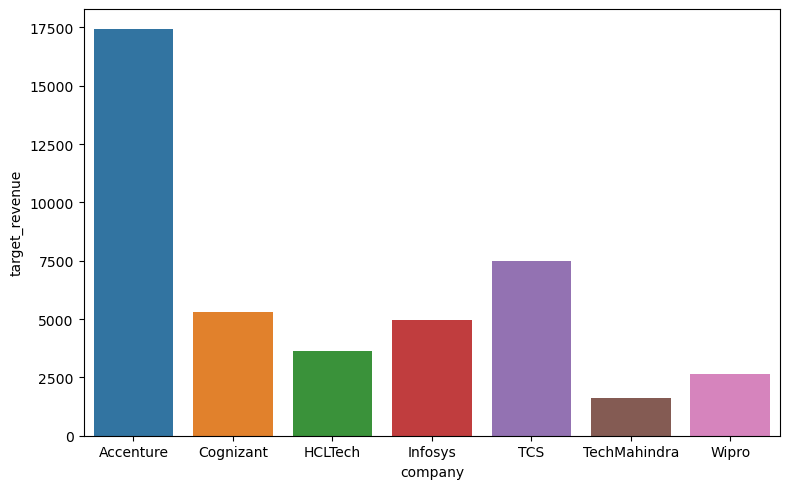

In [10]:
plt.figure(figsize=(8, 5))
sns.barplot(x=report['company'], y=report['target_revenue'])
plt.tight_layout()
plt.show()

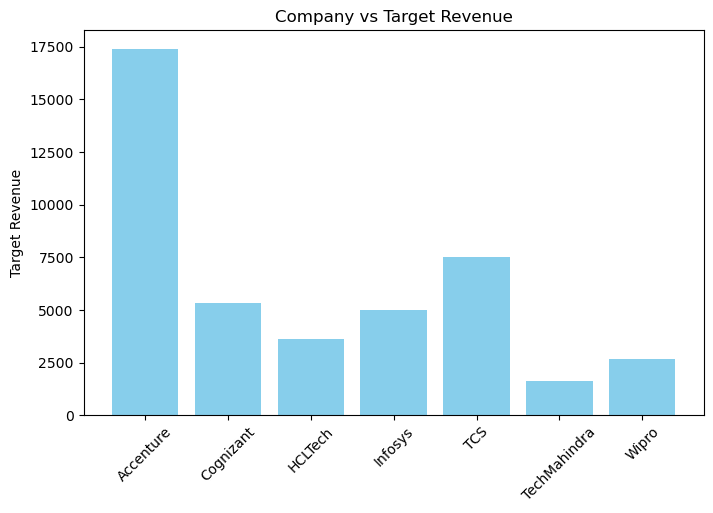

In [13]:
# Company vs Target Revenue
plt.figure(figsize=(8,5))
plt.bar(df['company'], df['target_revenue'], color='skyblue')
plt.xticks(rotation=45)
plt.ylabel("Target Revenue")
plt.title("Company vs Target Revenue")
plt.show()

In [17]:
df['revenue_range'].str.split(' - ').apply(lambda x: int(x[0]))

0    17050
1     5197
2     3541
3     4875
4     7341
5     1598
6     2602
Name: revenue_range, dtype: int64

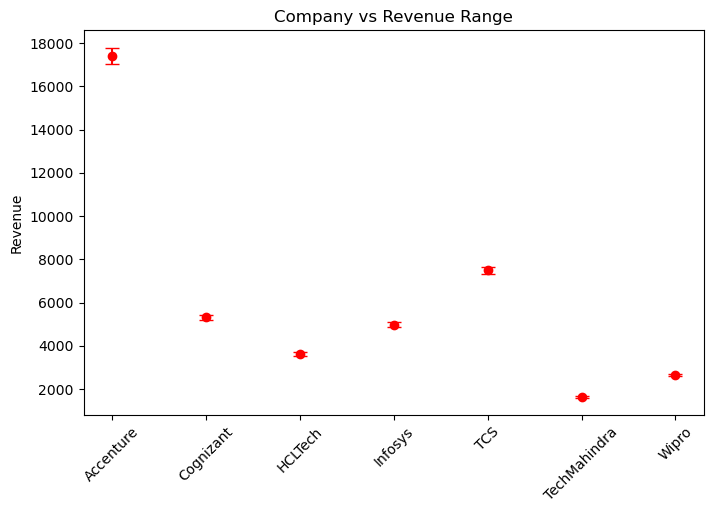

In [18]:
# Company vs Revenue Range
plt.figure(figsize=(8,5))
target = df['target_revenue']
low = df['revenue_range'].str.split(' - ').apply(lambda x: int(x[0]))
high = df['revenue_range'].str.split(' - ').apply(lambda x: int(x[1]))
plt.errorbar(df['company'], target, 
             yerr=[target - pd.Series(low), pd.Series(high) - target],
             fmt='o', capsize=5, color='red')
plt.xticks(rotation=45)
plt.ylabel("Revenue")
plt.title("Company vs Revenue Range")
plt.show()

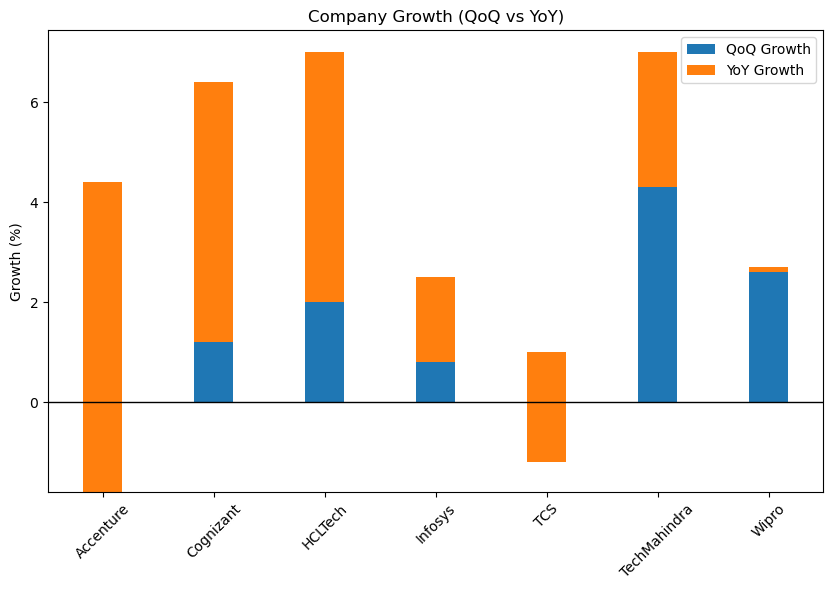

In [19]:
# Growth chart (QoQ & YoY)
plt.figure(figsize=(10,6))
plt.axhline(0, color='black', linewidth=1)
width = 0.35
plt.bar(df['company'], df['qoq_growth'], width, label='QoQ Growth')
plt.bar(df['company'], df['yoy_growth'], width, label='YoY Growth', bottom=df['qoq_growth'])
plt.xticks(rotation=45)
plt.ylabel("Growth (%)")
plt.title("Company Growth (QoQ vs YoY)")
plt.legend()
plt.show()